# King County House Prices: Refactored Notebook

This is the refactored copy of [King-County.ipynb](King-County.ipynb). The story is the same, but every cleaning, feature engineering and modeling step now lives in tested Python functions in [`src/king_county/`](src/king_county/). This notebook only calls those functions and shows the charts, so it runs top to bottom without hidden state.

| Module | Responsibility |
|---|---|
| `config.py` | paths, reference coordinates, thresholds, feature lists, model settings |
| `data_preparation.py` | loading and cleaning |
| `feature_engineering.py` | distances, price per square foot, sale date features |
| `transformers.py`, `pipeline.py` | the reusable scikit-learn pipeline |
| `modeling.py` | splits, baselines, grid search, error table, saving (also runs as a script) |
| `plots.py` | the map helper used below |

The problems found in the original notebook, and how each one was fixed, are listed in the [README](README.md).

The three maps are interactive Plotly charts. GitHub cannot draw them, so open the notebook in Jupyter or VS Code to see them.

## About this analysis

In this notebook, we will walk through the key stages of a Data Science workflow using a housing dataset from King County. You have already seen some of the early steps in a previous lecture. This time, we will go further by building and evaluating machine learning models.

As a quick reminder, here is the Data Science lifecycle:

<center><img src="./assets/DS_LC.png" alt="drawing" width="500"/></center>

The goal is to implement the essential steps of a supervised machine learning workflow with the Python library scikit-learn.  

We will use the following methods:  
- feature engineering,
- train/test split,
- model training,
- hyperparameter optimization with grid search and cross-validation,
- and model evaluation.

To make the workflow more concrete, we will use the following fictional scenario:

**You have just landed your dream job as a data scientist at an innovative company near Seattle. Before you move, you want to understand the local housing market and estimate fair property values so you can negotiate with confidence.**

```mermaid
flowchart LR
    A[Raw housing data] --> B[Data preparation]
    B --> C[Exploratory data analysis]
    C --> D[Feature engineering]
    D --> E[Model training]
    E --> F[Evaluation and tuning]
    F --> G[Save the final model]
```


![](assets/seattle_skyline.jpg)
(<span>Photo by <a href="https://unsplash.com/@phoebezzf?utm_source=unsplash&amp;utm_medium=referral&amp;utm_content=creditCopyText">Zhifei Zhou</a> on <a href="https://unsplash.com/s/photos/seattle-skyline?utm_source=unsplash&amp;utm_medium=referral&amp;utm_content=creditCopyText">Unsplash</a></span>)

**Rather than relying on intuition alone, we will use data to support the house-hunting process. Our aim is to predict home prices in and around Seattle so that we can estimate a realistic property value before negotiating.**

## Business Understanding

Seattle is located in King County, which is shown on the map below. To keep commuting time manageable, we limit the property search to this area.



![](assets/king_county_districts.jpeg)

(Photo from King County [imap](https://gismaps.kingcounty.gov/iMap/))

For this project, we use a dataset that contains property sales in King County from May 2014 to May 2015.

Before building any model, it is important to understand what information the dataset contains. The table below summarizes the available columns:

| **Column name** | **Description** |
|---|---|
| `id` | Unique identifier for a house sale |
| `date` | Date of sale |
| `price` | Sale price of the house |
| `bedrooms` | Number of bedrooms |
| `bathrooms` | Number of bathrooms; `.5` indicates a toilet room without a shower |
| `sqft_living` | Interior living area in square feet |
| `sqft_lot` | Lot size in square feet |
| `floors` | Number of floors |
| `waterfront` | Whether the house has a waterfront view (`0` = no, `1` = yes) |
| `view` | Index from `0` to `4` indicating the quality of the view |
| `condition` | Index from `1` to `5` describing the condition of the property |
| `grade` | Index from `1` to `13` describing construction and design quality |
| `sqft_above` | Interior living area above ground in square feet |
| `sqft_basement` | Basement area in square feet |
| `yr_built` | Year the house was built |
| `yr_renovated` | Year of the last renovation |
| `zipcode` | ZIP code of the property |
| `lat` | Latitude |
| `long` | Longitude |
| `sqft_living15` | Interior living area of the nearest 15 neighbors |
| `sqft_lot15` | Lot size of the nearest 15 neighbors |



## Setup

All logic is imported from `src/king_county`. The plotting libraries are only needed for the charts in this notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.king_county.data_preparation import (
    add_last_known_change,
    fill_missing_view_waterfront,
    load_data,
    missing_value_report,
    recompute_sqft_basement,
    remove_bath_bed_ratio_outliers,
)
from src.king_county.feature_engineering import (
    add_center_distance,
    add_price_per_sqft,
    add_sale_date_features,
    add_water_distance,
    get_waterfront_coordinates,
)
from src.king_county.modeling import (
    EXPERIMENTS,
    build_error_table,
    run_experiment,
    save_model,
    separate_target,
    split_randomly,
    train_and_score_baselines,
)
from src.king_county.plots import plot_house_map

In [2]:
houses = load_data()
houses.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,10/13/2014,221900.0,3,1.00,1180,5650,1.0,NaN,0.0,...,7,1180,0.0,1955,0.0,98178,47.5112,-122.257,1340,5650
1,6414100192,12/9/2014,538000.0,3,2.25,2570,7242,2.0,0.0,0.0,...,7,2170,400.0,1951,1991.0,98125,47.7210,-122.319,1690,7639
2,5631500400,2/25/2015,180000.0,2,1.00,770,10000,1.0,0.0,0.0,...,6,770,0.0,1933,NaN,98028,47.7379,-122.233,2720,8062
3,2487200875,12/9/2014,604000.0,4,3.00,1960,5000,1.0,0.0,0.0,...,7,1050,910.0,1965,0.0,98136,47.5208,-122.393,1360,5000
4,1954400510,2/18/2015,510000.0,3,2.00,1680,8080,1.0,0.0,0.0,...,8,1680,0.0,1987,0.0,98074,47.6168,-122.045,1800,7503


## Data Preparation

After loading the data, we need a reliable overview of its quality and structure.
We will answer the following questions:

- How many house sales are included in the dataset?
- What data types are present (`int`, `float`, `object`)?
- Are there any missing values?
- How many distinct values does each variable contain?



**1.** How many house sales are included in the dataset?



In [3]:
houses.shape

(21597, 21)

Each row represents one house sale.

The dataset contains 21597 sales records.



**2.** What data types are present (`int`, `float`, `object`)?
Which values look surprising?


In [4]:
houses.info()

<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21597 non-null  int64  
 1   date           21597 non-null  str    
 2   price          21597 non-null  float64
 3   bedrooms       21597 non-null  int64  
 4   bathrooms      21597 non-null  float64
 5   sqft_living    21597 non-null  int64  
 6   sqft_lot       21597 non-null  int64  
 7   floors         21597 non-null  float64
 8   waterfront     19221 non-null  float64
 9   view           21534 non-null  float64
 10  condition      21597 non-null  int64  
 11  grade          21597 non-null  int64  
 12  sqft_above     21597 non-null  int64  
 13  sqft_basement  21597 non-null  str    
 14  yr_built       21597 non-null  int64  
 15  yr_renovated   17755 non-null  float64
 16  zipcode        21597 non-null  int64  
 17  lat            21597 non-null  float64
 18  long           21

Our dataset contains 8 floating-point columns, 11 integer columns, and 2 text columns (pandas 3 shows them as `str`).
We would normally expect variables such as sizes, room counts, indexes, and geographic information to be stored as numeric values.

The `date` column is stored as text, which is reasonable at this stage, but `sqft_basement` is also stored as text. That is surprising.
When we inspect the data more closely, we can see why: the column contains `?` values, so pandas cannot interpret the full column as numeric.

**3.** Are there any missing values?

In [5]:
missing_value_report(houses)

,count,percentage
waterfront,2376,11.00
view,63,0.29
yr_renovated,3842,17.79


We have missing values in the columns `waterfront`, `view`, and `yr_renovated`.
The largest share of missing values appears in `yr_renovated`.

We will need to decide how to handle each of these columns carefully, because different kinds of missing values call for different strategies.



**4.** How many distinct values does each variable contain?



In [6]:
houses.nunique()

id               21420
date               372
price             3622
bedrooms            12
bathrooms           29
sqft_living       1034
sqft_lot          9776
floors               6
waterfront           2
view                 5
condition            5
grade               11
sqft_above         942
sqft_basement      304
yr_built           116
yr_renovated        70
zipcode             70
lat               5033
long               751
sqft_living15      777
sqft_lot15        8682
dtype: int64

Interesting findings:

**1.** We have 21420 distinct house IDs for 21597 sales: 176 houses were sold more than once. This matters for modeling: a random train/test split can put two sales of the same house on both sides.

**2.** We observe 3622 distinct sale prices, so many properties were sold for the same price.

**3.** Although `grade` is defined on a scale from 1 to 13, only 11 distinct values appear in the dataset.

**4.** The houses in our dataset were built across 116 different years.

Next, we can look at the distribution of the variables in more detail.

`kc_data.describe()` reports the following summary statistics:
- **count**: number of non-missing values
- **mean**: arithmetic average
- **std**: standard deviation
- **min**: smallest observed value
- **25%**: first quartile
- **50%**: median
- **75%**: third quartile
- **max**: largest observed value

These values help us spot outliers, skewed distributions, and variables that may need additional cleaning or transformation.



In [7]:
houses.describe().round(2)

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.159700e+04,21597.00,21597.00,21597.00,21597.00,21597.00,21597.00,19221.00,21534.00,21597.00,21597.00,21597.00,21597.00,17755.00,21597.00,21597.00,21597.00,21597.00,21597.00
mean,4.580474e+09,540296.57,3.37,2.12,2080.32,15099.41,1.49,0.01,0.23,3.41,7.66,1788.60,1971.00,83.64,98077.95,47.56,-122.21,1986.62,12758.28
std,2.876736e+09,367368.14,0.93,0.77,918.11,41412.64,0.54,0.09,0.77,0.65,1.17,827.76,29.38,399.95,53.51,0.14,0.14,685.23,27274.44
min,1.000102e+06,78000.00,1.00,0.50,370.00,520.00,1.00,0.00,0.00,1.00,3.00,370.00,1900.00,0.00,98001.00,47.16,-122.52,399.00,651.00
25%,2.123049e+09,322000.00,3.00,1.75,1430.00,5040.00,1.00,0.00,0.00,3.00,7.00,1190.00,1951.00,0.00,98033.00,47.47,-122.33,1490.00,5100.00
50%,3.904930e+09,450000.00,3.00,2.25,1910.00,7618.00,1.50,0.00,0.00,3.00,7.00,1560.00,1975.00,0.00,98065.00,47.57,-122.23,1840.00,7620.00
75%,7.308900e+09,645000.00,4.00,2.50,2550.00,10685.00,2.00,0.00,0.00,4.00,8.00,2210.00,1997.00,0.00,98118.00,47.68,-122.12,2360.00,10083.00
max,9.900000e+09,7700000.00,33.00,8.00,13540.00,1651359.00,3.50,1.00,4.00,5.00,13.00,9410.00,2015.00,2015.00,98199.00,47.78,-121.32,6210.00,871200.00


Interesting findings:

**1.** The average sale price is $540,296. The most expensive house sold for $7,700,000, while the cheapest sold for $78,000.

**2.** Half of the houses have 3 bedrooms or fewer. The maximum value is 33 bedrooms, which immediately looks suspicious.

**3.** On average, a house has about 2.1 bathrooms and 3.4 bedrooms.

**4.** 75% of houses have 2 floors or fewer.

**5.** Only about 1% of the houses have a waterfront view. Because `waterfront` is binary, its mean can be interpreted as a proportion.

**6.** The oldest house in the dataset dates from 1900, while the newest dates from 2015.



We could extract many more insights from the summary table, but we have already identified a few issues that should be handled during data cleaning:

- missing values
- the `?` entry in `sqft_basement`
- the record with 33 bedrooms

The remaining distributions will be easier to interpret later with charts. For now, we will focus on cleaning the data.



**33 bedrooms**

The maximum bedroom count points to a property with 33 bedrooms but fewer than 2 bathrooms.

In [8]:
houses.query("bedrooms == 33")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
15856,2402100895,6/25/2014,640000.0,33,1.75,1620,6000,1.0,0.0,0.0,...,7,1040,580.0,1947,0.0,98103,47.6878,-122.331,1330,4700


A house with 33 bedrooms, 1.75 bathrooms, and only 1,620 square feet is extremely unlikely, so this record is probably a data-entry error.

The original notebook dropped it by its row number (`drop(15856)`), which silently removes the wrong house as soon as the file or the row order changes. Instead, we remove every house with an implausible ratio of bathrooms to bedrooms (at most 0.10, or at least 2). The rule catches the 33-bedroom house and a few more rows.

In [9]:
rows_before = len(houses)
houses = remove_bath_bed_ratio_outliers(houses)
print(f"Removed {rows_before - len(houses)} houses, {len(houses)} remain.")

Removed 13 houses, 21584 remain.


**`?` in `sqft_basement`**

From the output of `.info()`, we can see that `sqft_basement` is stored as an object rather than a numeric value. The reason is that at least one row contains `?` instead of a number.

We will reconstruct the basement size as `sqft_living - sqft_above`.



In [10]:
houses = recompute_sqft_basement(houses)

**Missing values**


In [11]:
missing_value_report(houses)

,count,percentage
waterfront,2373,10.99
view,63,0.29
yr_renovated,3841,17.80


After replacing the invalid basement entries, three variables still contain missing values: `waterfront` (about 11%), `view` (about 0.3%), and `yr_renovated` (about 18%).

For `view` and `waterfront`, the value 0 is by far the most common category, so replacing the missing values with 0 is a reasonable simplification.

In [12]:
houses["view"].value_counts()

view
0.0    19411
2.0      955
3.0      508
1.0      330
4.0      317
Name: count, dtype: int64

In [13]:
houses["waterfront"].value_counts()

waterfront
0.0    19065
1.0      146
Name: count, dtype: int64

In [14]:
houses = fill_missing_view_waterfront(houses)
missing_value_report(houses)

,count,percentage
yr_renovated,3841,17.8


Because `yr_renovated` has a relatively large number of missing values, we do not simply fill it with a single constant. Instead, we combine `yr_built` and `yr_renovated` into a new feature called `last_known_change`, then remove the original two columns.



In [15]:
houses = add_last_known_change(houses)
houses["last_known_change"].describe()

count    21584.000000
mean      1972.944218
std         28.947673
min       1900.000000
25%       1954.000000
50%       1977.000000
75%       1999.000000
max       2015.000000
Name: last_known_change, dtype: float64

At this point, the main data cleaning steps are complete.

Commands such as `.describe()` already gave us a quick statistical overview, but exploratory data analysis becomes much easier once we visualize the distributions directly.



## Exploratory Data Analysis

Now we move from cleaning to exploration.
Histograms are a useful first step because they show how each variable is distributed and whether a variable behaves more like a continuous measure or a category.



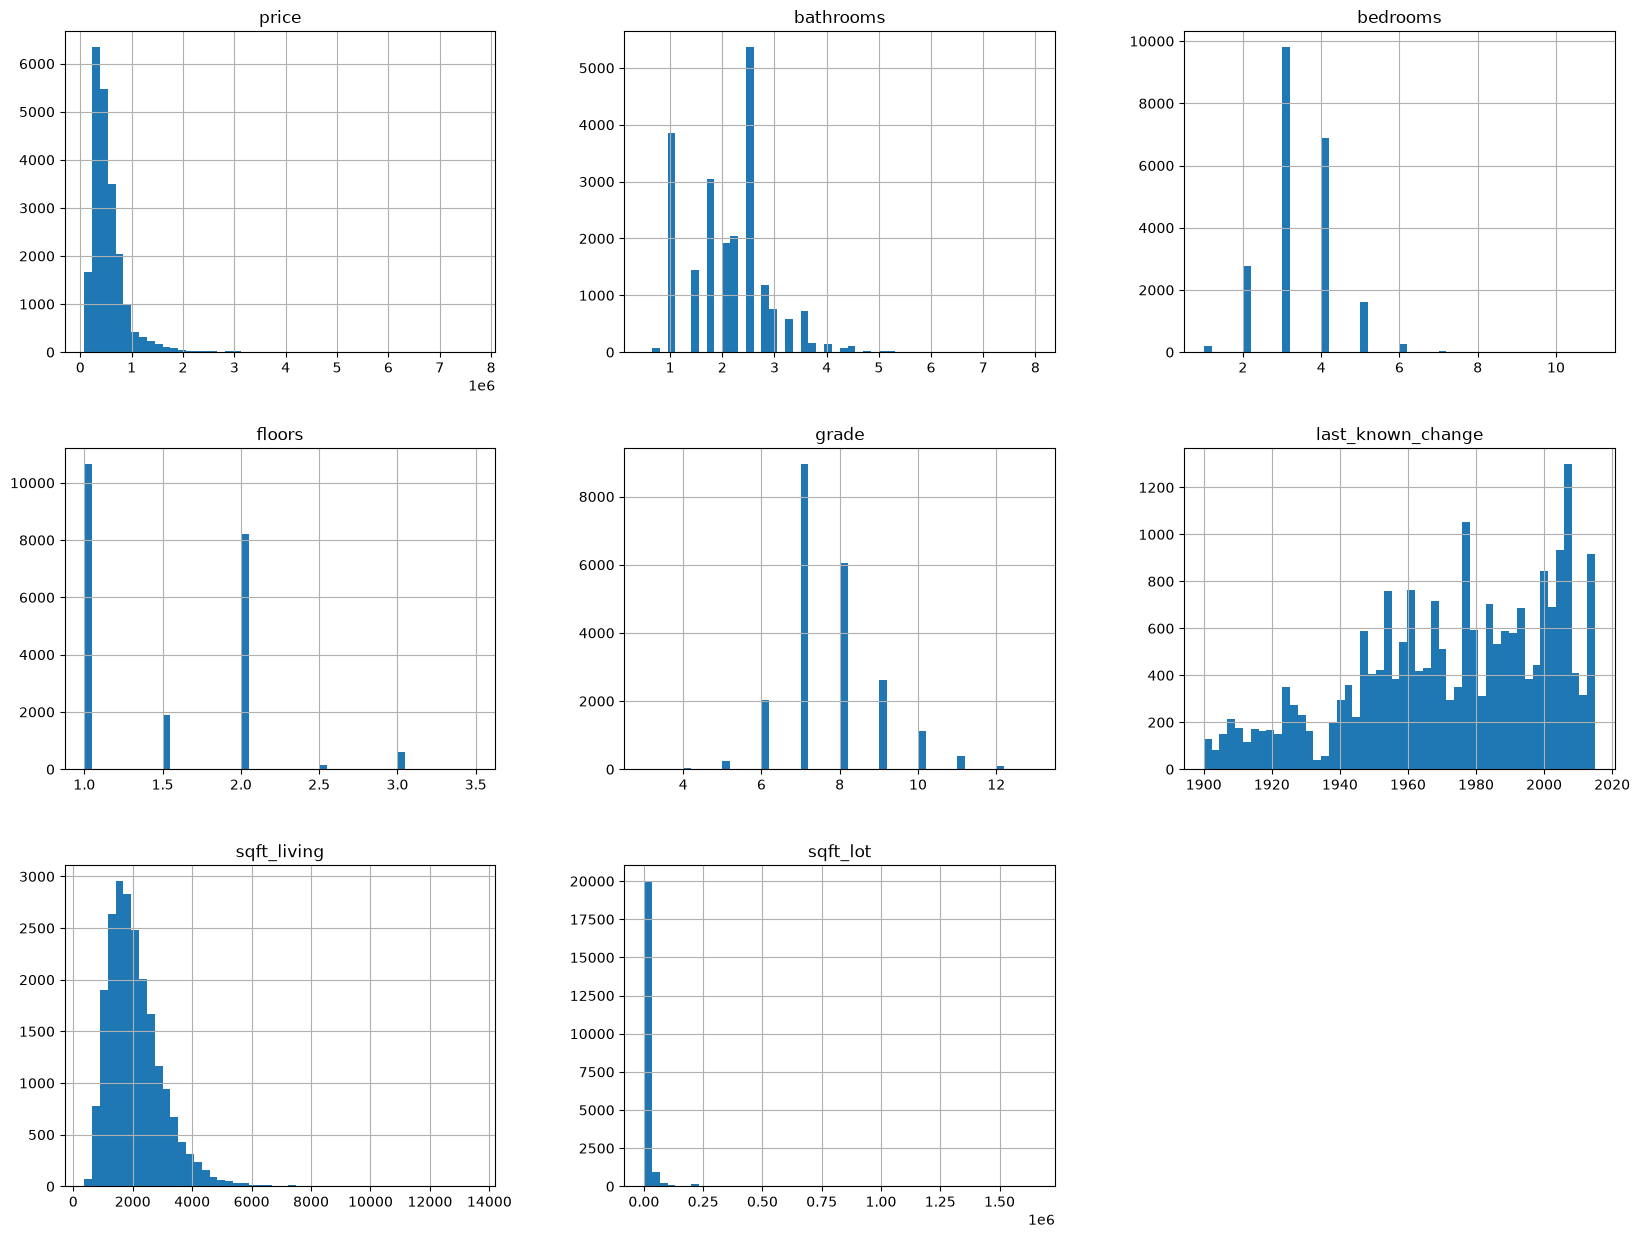

In [16]:
columns_histogram = [
    "price",
    "bathrooms",
    "bedrooms",
    "floors",
    "grade",
    "last_known_change",
    "sqft_living",
    "sqft_lot",
]
houses[columns_histogram].hist(bins=50, figsize=(20, 15))
plt.show()

Histograms help us understand both the overall distribution and the rough shape of each variable.

Findings:
- `price` is right-skewed, with a small number of very expensive houses stretching the distribution.
- More than 5000 houses have 2.5 bathrooms. In the U.S., `.5` typically indicates a toilet room without a shower.
- Most houses have between 2 and 5 bedrooms, with 3 bedrooms being the most common.
- Most houses have only one floor.
- Most houses have a grade between 6 and 10 on the 1 to 13 scale.
- Very few houses were built or renovated between 1930 and 1940. Construction increases noticeably after that period.
- `sqft_living` is also somewhat right-skewed.
- Extreme lot sizes distort the lot-area histogram, which makes the main distribution harder to see.

Another useful view is the box plot, which displays the same summary statistics graphically.



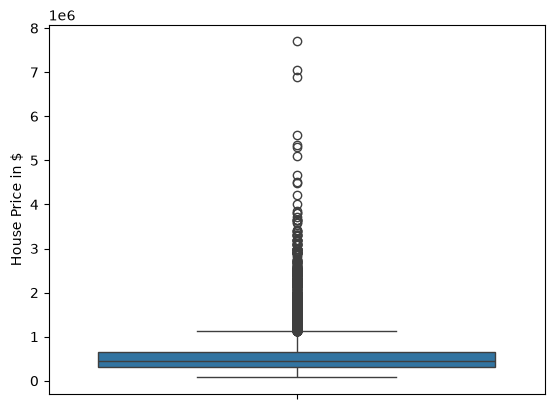

In [17]:
sns.boxplot(y=houses["price"])
plt.ylabel("House Price in $")
plt.show()

If we try the box plot with different columns, we can clearly see outliers in several variables.  

Outliers matter because they can strongly affect model quality, but they should not be removed automatically.

For the property with 33 bedrooms, the value was implausible enough to treat it as an error and remove the row (together with the other implausible bathroom-to-bedroom ratios).
By contrast, very expensive houses are rare but believable in the Seattle area, so we keep them.

This is a good example of why domain knowledge matters: **an unusual value is not always a wrong value**.



It is also useful to inspect relationships between variables.
A pair plot gives a quick overview by plotting each variable against the others and showing the univariate distributions on the diagonal.

When reading the pair plot, we are especially interested in possible relationships such as:
- how price changes as living area increases
- whether better grades are associated with higher prices
- whether some features appear to move together



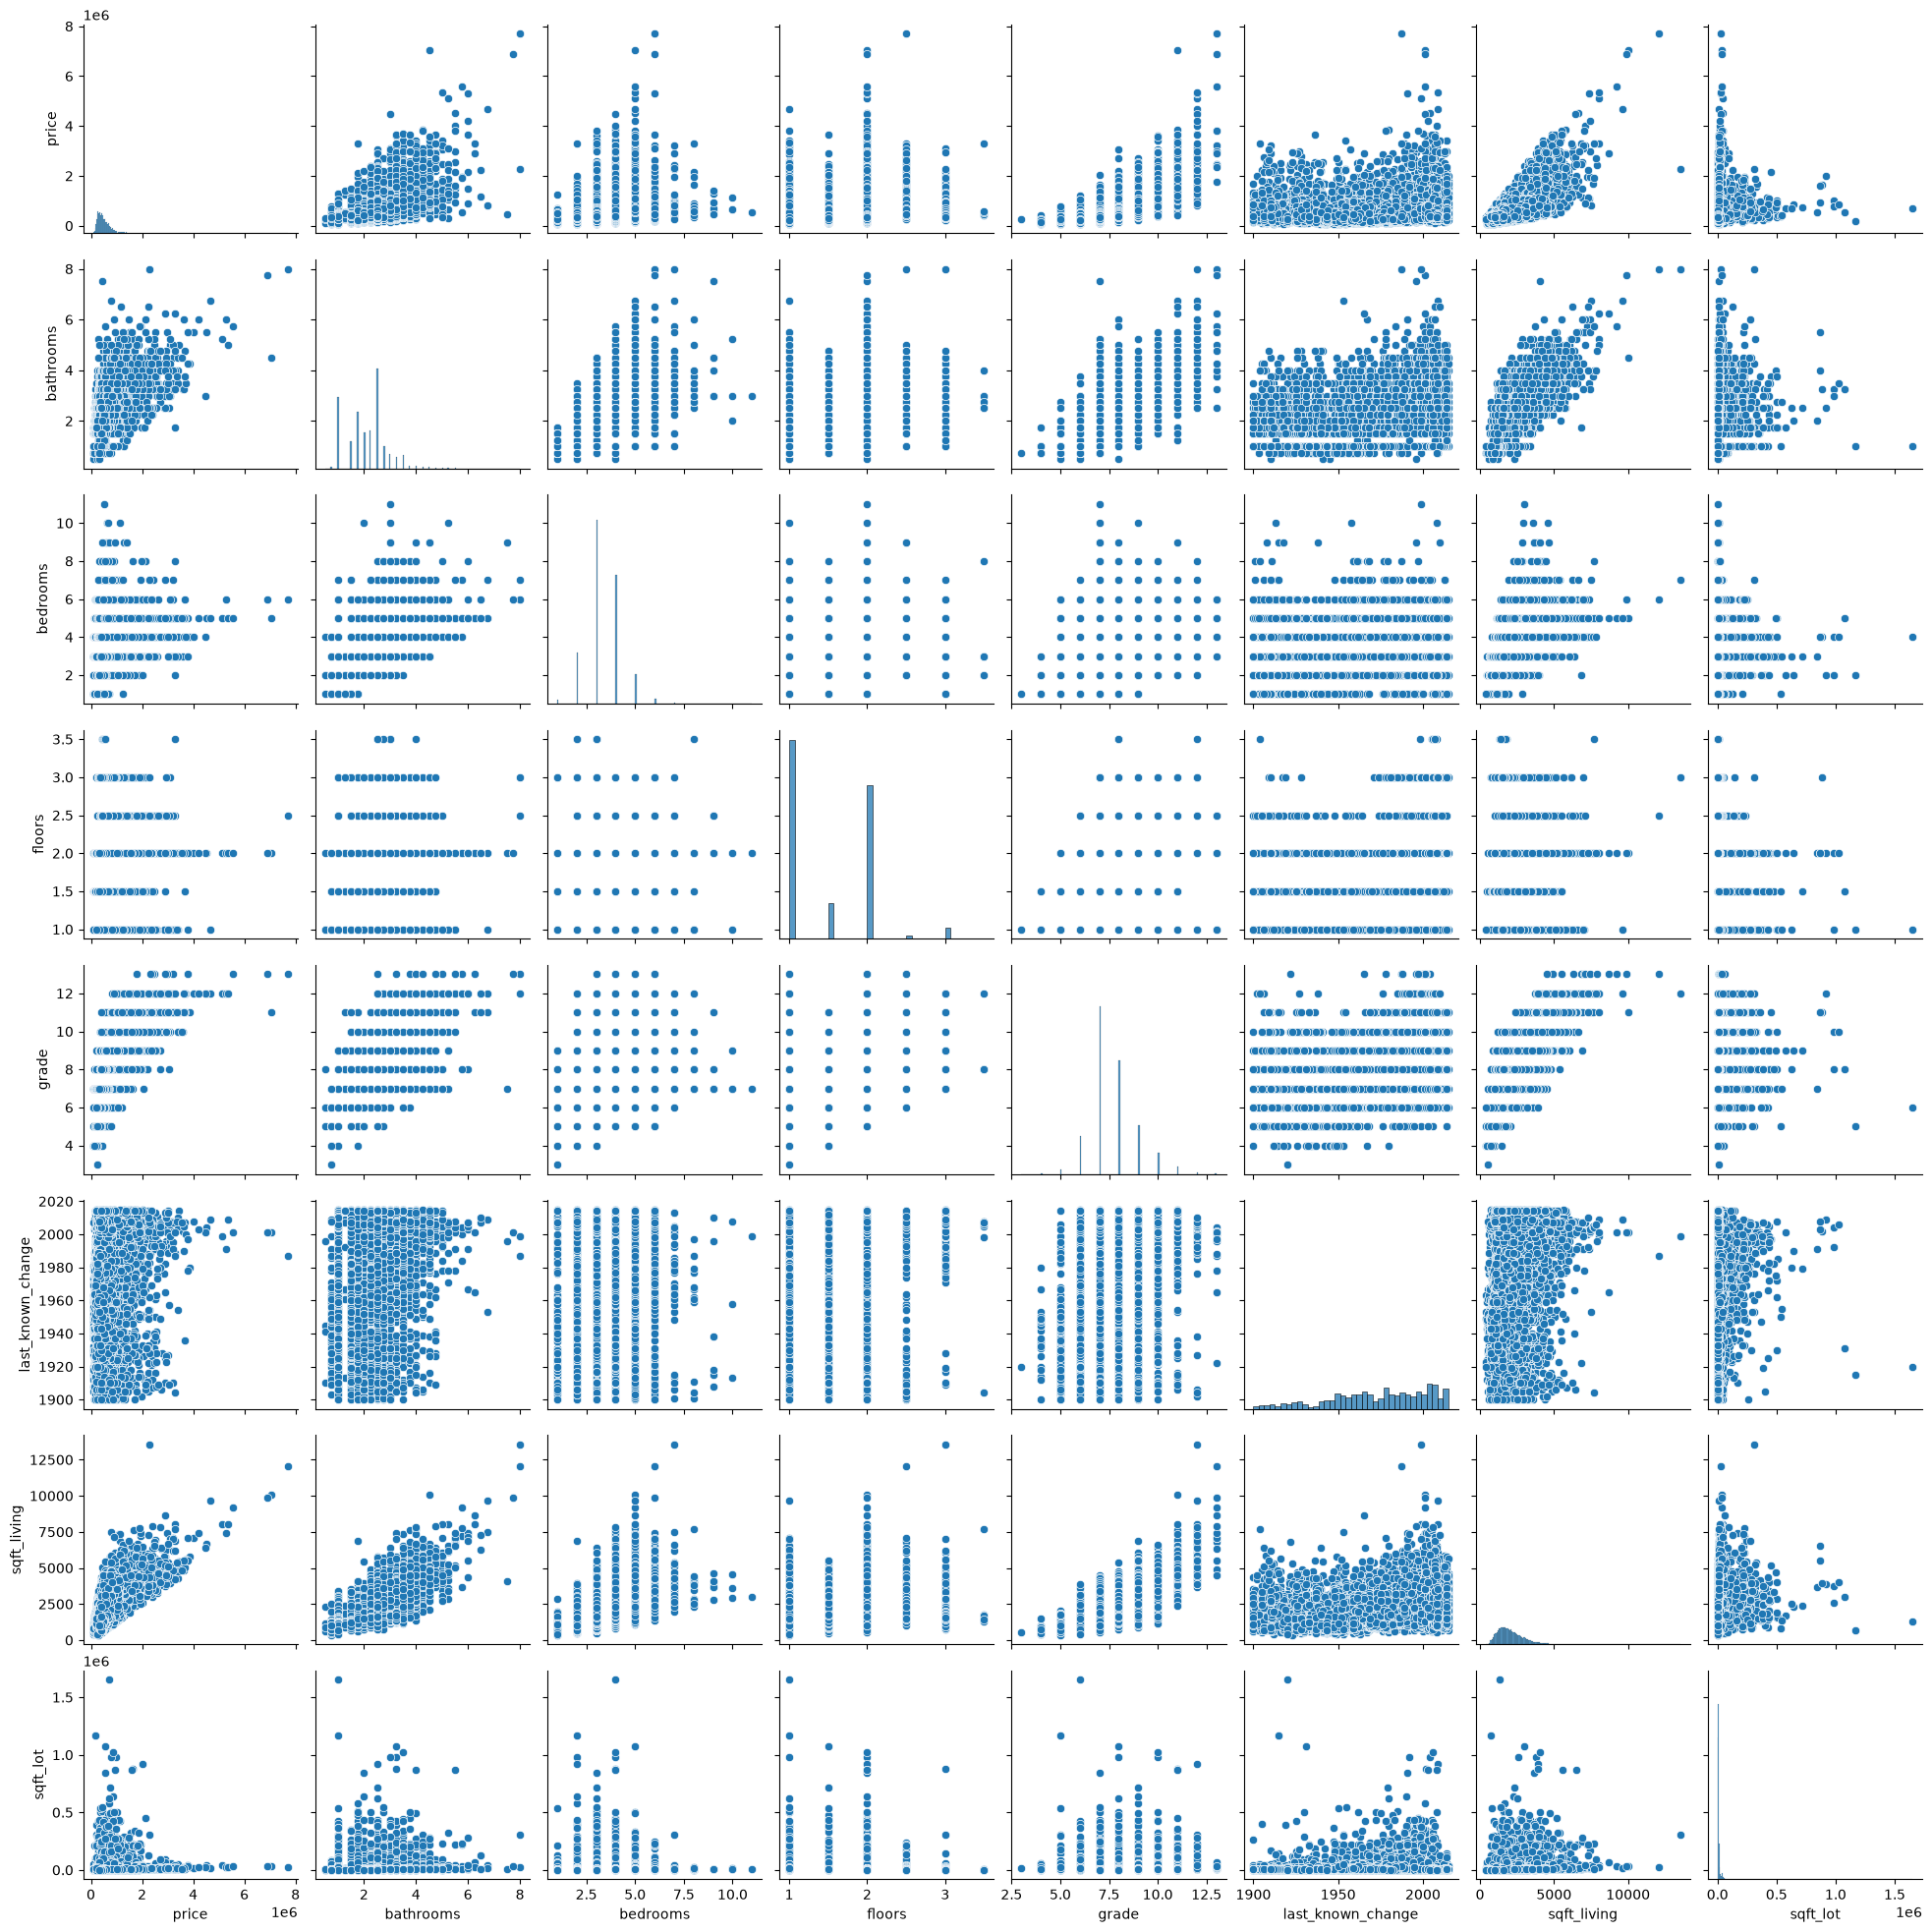

In [18]:
sns.pairplot(houses[columns_histogram]);

A heatmap provides another view of correlation, this time by summarizing the linear relationship between every pair of variables.

Strong red tones indicate positive correlation, while strong blue tones indicate negative correlation. For example:
- larger living area is often associated with higher price

**Correlation does not prove causation**, but it helps us identify promising variables for a linear model.



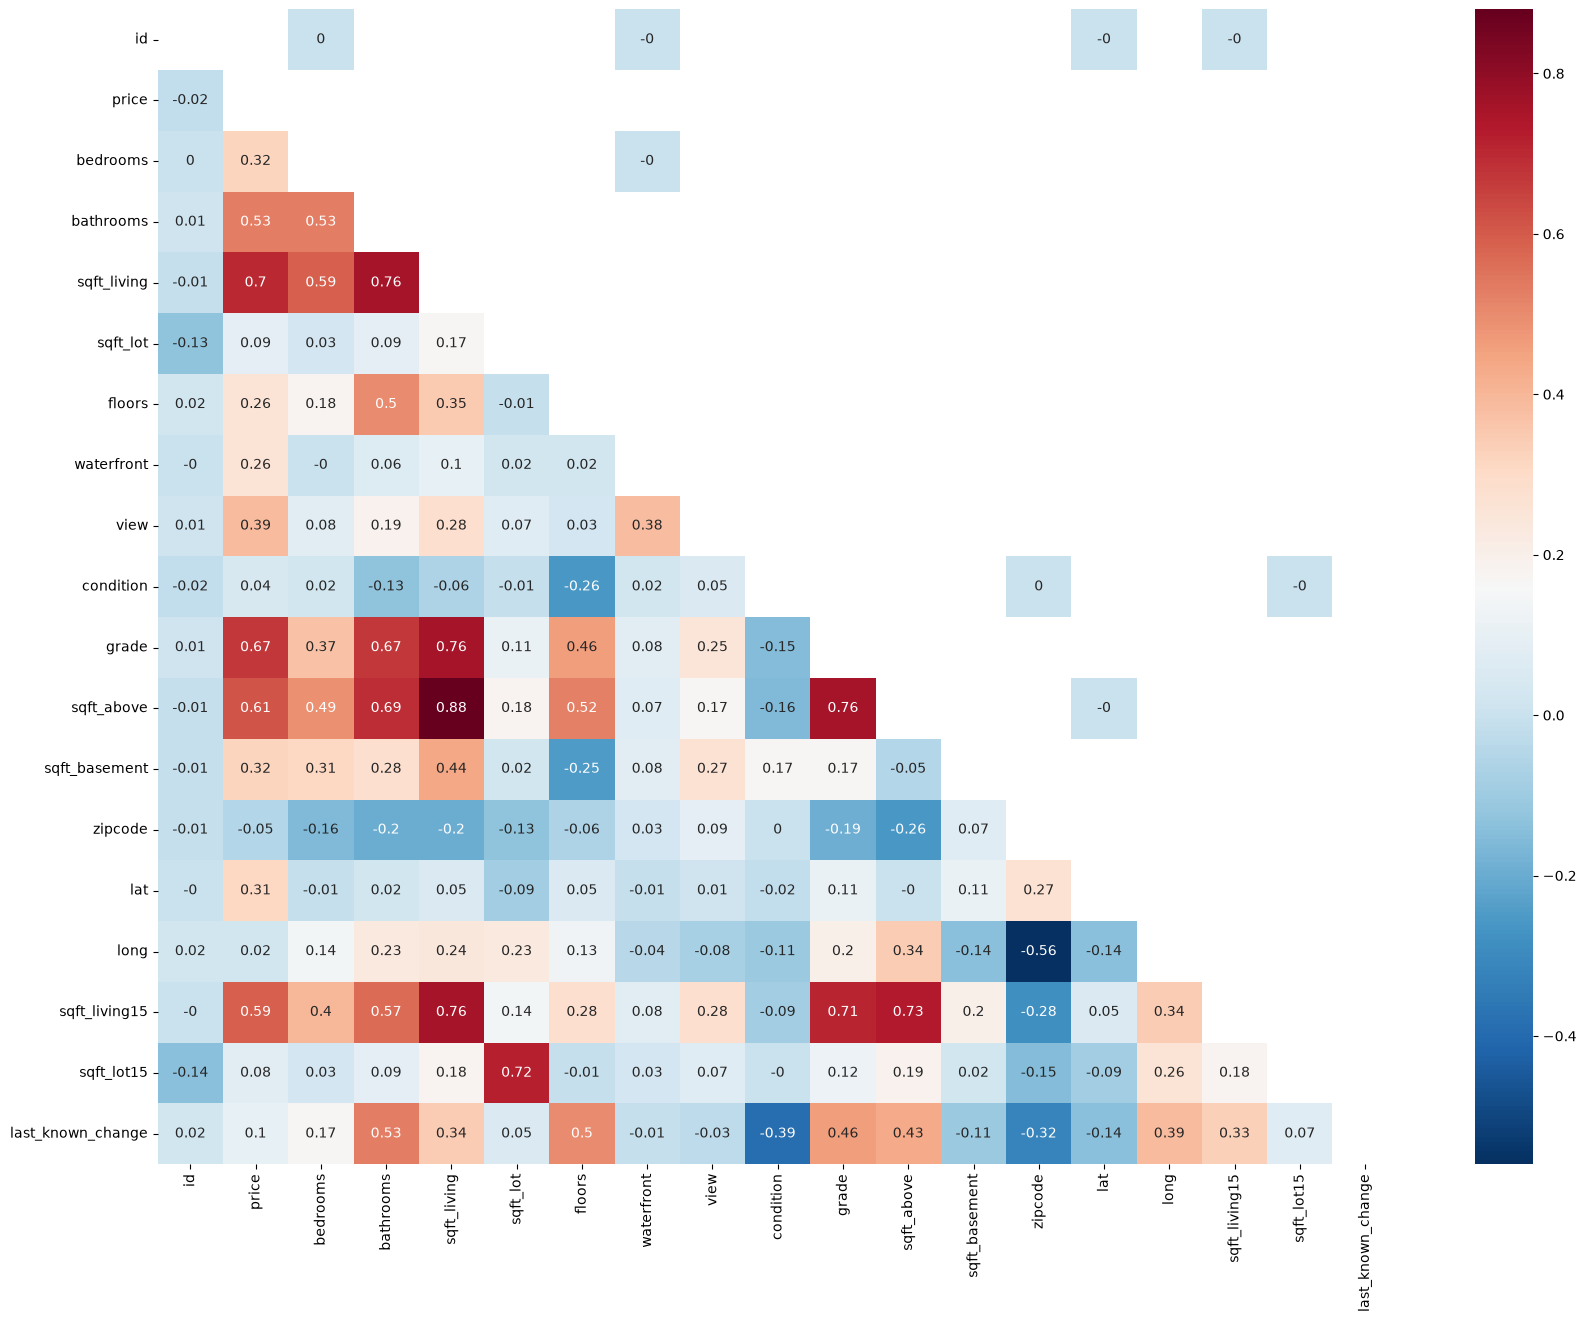

In [19]:
numeric_houses = houses.select_dtypes(include=["number"])
correlations = numeric_houses.corr().round(2)
plt.figure(figsize=(20, 15))
sns.heatmap(correlations, annot=True, mask=np.triu(correlations), cmap="RdBu_r");

## Feature Engineering

Feature engineering means creating new variables that may explain the target more clearly or improve predictive performance.

Buyers often think in terms of value for money rather than total price alone, so for exploration we add the **price per square foot of living space** (`sqft_price`). It is calculated from the price itself, so it is only used for charts, never as a model input: the model would simply read the answer from it. The model target stays the sale `price`.

The original notebook divided the price by living area **plus lot area**, which does not match its own description. `add_price_per_sqft()` divides by living area only.

In [20]:
houses = add_price_per_sqft(houses)

**Distance to the center of wealth**

One possible explanatory feature is the distance to a highly desirable area. As a simple proxy, we use Bill Gates' residence in Medina, on Lake Washington, as a rough "center of wealth".
According to Wikipedia, the estate has an estimated value of about **US$147.5 million**.

<center><a href="https://en.wikipedia.org/wiki/Bill_Gates%27s_house#/media/File:Residence_of_Bill_Gates.jpg"><img src="https://upload.wikimedia.org/wikipedia/commons/2/26/Residence_of_Bill_Gates.jpg" alt="Bill Gates residence" width="700"></a></center>

To create this feature, we compute the geographic distance between each house and that reference point with `distance_km()`.
It corrects longitude by `cos(lat)` because the physical distance represented by one degree of longitude depends on latitude.
The original notebook used two different latitudes for the same reference point (47.62774 for the point, 47.6219 for the correction) and wrote the formula twice. Now there is one function and one set of constants in `config.py`.


In [21]:
houses = add_center_distance(houses)

The most expensive house per square foot, and overall:

In [22]:
houses.nlargest(1, "sqft_price")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,last_known_change,sqft_price,center_distance
19321,6021500970,4/7/2015,874950.0,2,1.0,1080,4000,1.0,0.0,0.0,...,1080,0,98117,47.6902,-122.387,1530,4240,1940,810.14,12.9141


In [23]:
houses.nlargest(1, "price")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,last_known_change,sqft_price,center_distance
7245,6762700020,10/13/2014,7700000.0,6,8.0,12050,27600,2.5,0.0,3.0,...,8570,3480,98102,47.6298,-122.323,3940,8800,1987,639.0,6.085571


Now let us check whether this assumption is supported by the data: are properties closer to the wealth center generally more expensive?



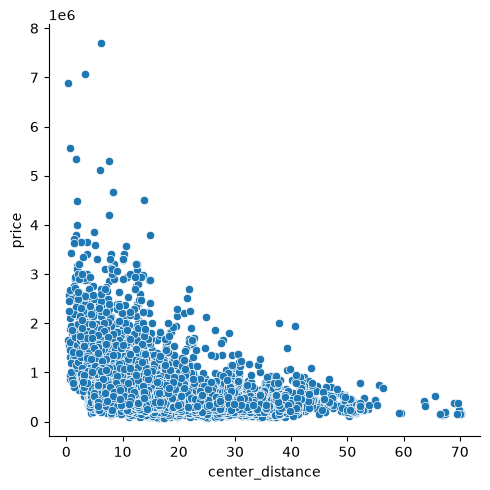

In [24]:
sns.relplot(y="price", x="center_distance", data=houses);

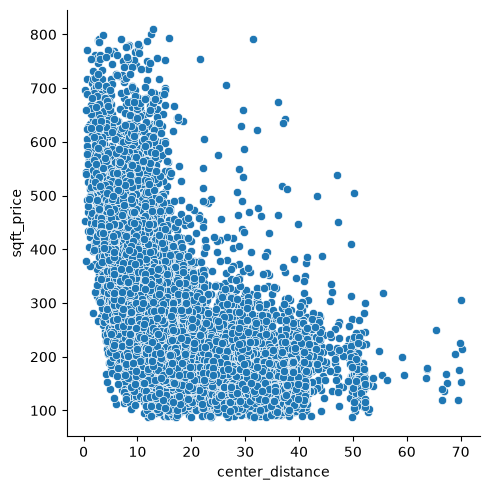

In [25]:
sns.relplot(y="sqft_price", x="center_distance", data=houses);

The charts support our hypothesis: price tends to decrease as distance from the wealth center increases.
The price-performance ratio also improves with distance, because the price per square foot tends to fall.

We can also plot all houses on a map of King County.
The color indicates how close each house is to the wealth center, while the marker size reflects sale price.



In [26]:
plot_house_map(
    houses,
    color="center_distance",
    hover_data=["sqft_price", "sqft_living", "zipcode", "floors"],
    size="sqft_price",
)

**Distance to the waterfront**

Next, we construct a rough measure of water proximity. We take all houses with `waterfront == 1` as reference points and compute, for every house, the distance to the nearest one.

This is only an approximation, because waterfront houses do not describe the entire shoreline perfectly, but it still gives us a useful proxy for how close a property is to the water.

The original notebook did this with a nested Python loop: about 3.2 million function calls and roughly 20 seconds. `add_water_distance()` computes one distance matrix with NumPy instead and needs a fraction of a second.

Here, for exploration, all houses serve as reference points. In the model pipeline, `WaterDistanceTransformer` learns the reference points from the training rows only, so test houses never influence the training features.

In [27]:
houses = add_water_distance(houses, get_waterfront_coordinates(houses))
houses[["center_distance", "water_distance"]].describe().round(2)

,center_distance,water_distance
count,21584.00,21584.00
mean,17.53,5.54
std,10.15,5.93
min,0.34,0.00
25%,10.33,1.91
50%,14.46,3.41
75%,22.53,6.35
max,70.19,57.43


On average, the houses are about 17.5 km from the wealth center and 5.5 km from the nearest waterfront house. The house farthest from the wealth center is roughly 70 km away.

These values match the original notebook's output exactly, which confirms that the refactored functions compute the same features. (The original notebook's text said "almost 19 km" from the water, which did not match its own output.)

Again, we can test whether proximity to the water appears to influence price.

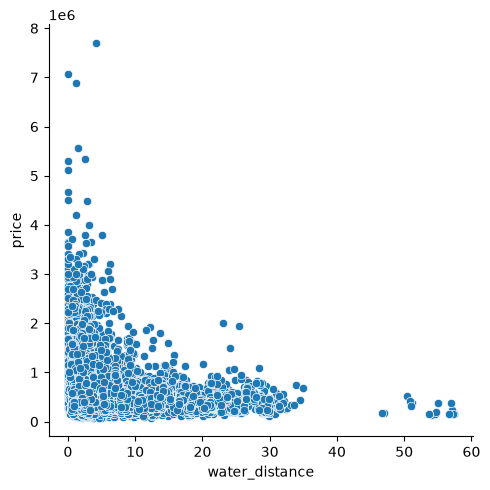

In [28]:
sns.relplot(y="price", x="water_distance", data=houses);

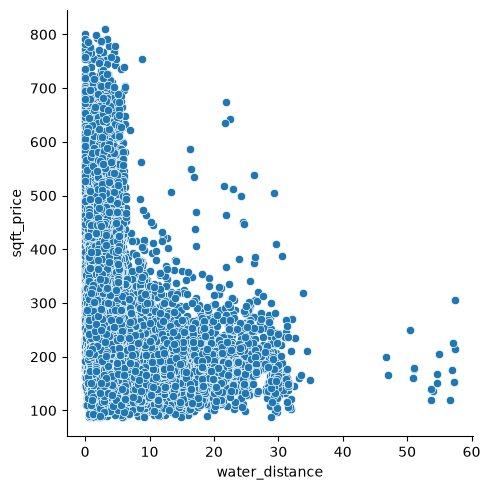

In [29]:
sns.relplot(y="sqft_price", x="water_distance", data=houses);

These charts again support our hypothesis: price tends to decrease as distance from the water increases, and the price per square foot also falls.

The map offers an additional sanity check. Houses close to the water should have small `water_distance` values, and that is exactly what we see.



In [30]:
plot_house_map(
    houses.query("water_distance <= 5"),
    color="water_distance",
    hover_data=["sqft_price", "sqft_living", "zipcode", "floors"],
    size="sqft_price",
    zoom=8.4,
)

**Sale date**

The original notebook dropped the sale `date` entirely. We extract the sale year and month to check whether prices follow the seasons.

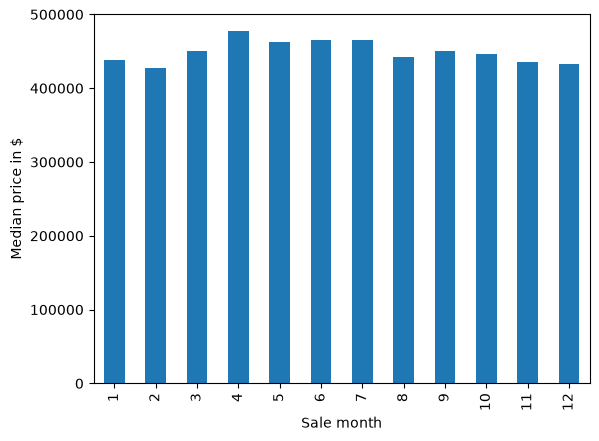

In [31]:
houses = add_sale_date_features(houses)
houses.groupby("sale_month")["price"].median().plot(
    kind="bar", xlabel="Sale month", ylabel="Median price in $"
)
plt.show()

Prices do follow the seasons: the median sale price peaks in April (about $477,000) and stays high until July, while February is the cheapest month (about $427,000, roughly 10% lower). The data only covers May 2014 to May 2015, so the sale year mostly separates the two halves of that window.

# Modeling

Our goal is to predict a house's sale **price** from information that is known before the sale. (The original notebook's text said the model predicts price per square foot, but its code always used `price` as the target.)

The modeling code lives in [`src/king_county/modeling.py`](src/king_county/modeling.py) and also runs as a script: `uv run python -m src.king_county.modeling`. Here we call the same functions step by step.

All cleaning and feature engineering steps run inside **one scikit-learn pipeline**. The saved model therefore accepts raw rows exactly like the CSV, and can price a single new house:

```mermaid
flowchart LR
    A[Raw house rows] --> B[recompute_sqft_basement]
    B --> C[fill_missing_view_waterfront]
    C --> D[add_last_known_change]
    D --> E[add_sale_date_features]
    E --> F[add_center_distance]
    F --> G["WaterDistanceTransformer<br/>(learns waterfront points in fit)"]
    G --> H{ColumnTransformer}
    H -->|numeric| I[PolynomialFeatures + StandardScaler]
    H -->|zipcode, sale_month| J[OneHotEncoder]
    I --> K["ElasticNet<br/>(on a standardized price)"]
    J --> K
```

We start again from the raw data and only remove the implausible rows. Row removal stays outside the pipeline: a pipeline step cannot drop rows without breaking the pairing of features and prices, and at prediction time we never want to drop the house we were asked to price.

In [32]:
model_houses = remove_bath_bed_ratio_outliers(load_data())

## Baselines

The notebook's three linear regressions, on the same random 70/30 split (`random_state=42`). Each one is the feature pipeline plus a `LinearRegression`.

In [33]:
train_and_score_baselines(*split_randomly(model_houses))

,model,test_r2,test_adj_r2
0,Linear: grade,0.448,0.448
1,Linear: grade + last_known_change,0.506,0.505
2,"Linear: all features, squared terms",0.882,0.879


**R²** measures the share of the variance in the price that the model explains (`1.0` = everything, `0.0` = nothing). **Adjusted R²** also accounts for the number of predictors, which makes models of different complexity comparable.

Using only `grade` explains about 45% of the variance in price on the test set, and adding the age-related `last_known_change` raises that to about 51%.

With squared terms of all features, the plain linear regression reaches **0.88**. The original notebook reported 0.75 for this model. The difference is not the data: on the notebook's exact rows and split, the unscaled version scores 0.76 and the scaled one 0.88. Squared features such as `sqft_lot²` reach values around 10¹², next to values below 1 for other features. Numbers that far apart in size make the least-squares calculation lose precision. The `StandardScaler` inside the pipeline puts every feature on the same scale and fixes that.

## Regularization, Tuning, and the Fixes Step by Step

After adding squared features, the model has many more inputs. **Regularization** shrinks coefficients and can push weak ones to zero, which helps when a model starts to learn noise (**overfitting**). Here we use [ElasticNet](https://scikit-learn.org/stable/modules/linear_model.html#elastic-net), which combines L1 and L2 regularization, and pick its strength with [grid search](https://scikit-learn.org/stable/modules/grid_search.html#grid-search) and 5-fold [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation) on the training rows only. A [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html) standardizes the price during training and converts predictions back to dollars.

Each experiment adds one fix on top of the previous one, so we can see what each change does:

| Experiment | What changes |
|---|---|
| 1 | The notebook's model, with the bugs fixed and a wider `alpha` grid (the original grid always picked its smallest value, 0.01) |
| 2 | Split **by house id**: all sales of the same house land on the same side of the split, in train/test and in the cross-validation folds |
| 3 | `zipcode` is **one-hot encoded** instead of being treated as a number (98199 is not "more" than 98001) |
| 4 | Sale **year and month** are added (final model) |

`cv_r2` is the mean over the 5 cross-validation folds; `test_r2` is measured once on the held-out test houses.

In [34]:
results = pd.DataFrame([run_experiment(experiment, model_houses) for experiment in EXPERIMENTS])
results[["experiment", "cv_r2", "test_r2", "best_params"]]

,experiment,cv_r2,test_r2,best_params
0,"1. Notebook model, bugs fixed (random split)",0.840,0.852,"{'model__regressor__alpha': 0.001, 'model__reg..."
1,2. + split by house id,0.844,0.837,"{'model__regressor__alpha': 0.001, 'model__reg..."
2,3. + zipcode one-hot encoded,0.879,0.873,"{'model__regressor__alpha': 0.001, 'model__reg..."
3,4. + sale year and month (final model),0.881,0.875,"{'model__regressor__alpha': 0.001, 'model__reg..."


What each fix did:

- **1, the notebook's model with bugs fixed:** test R² 0.852 (original notebook: 0.844). The best `alpha` is now 0.001, one step below the old grid's smallest value.
- **2, split by house:** test R² drops to 0.837, while the cross-validated score barely moves (0.840 to 0.844). Only about 1.6% of the rows are repeat sales, so the leak was small and most of the gap comes from a different test sample. The split is still the right choice, because it removes a known leak.
- **3, zipcode one-hot encoded:** the one big gain, about +0.035 in both cross-validation (0.879) and test (0.873). Location matters, and a postal code only carries that information once it is treated as a category.
- **4, sale year and month:** +0.002, within the noise of a single split. The seasonal effect we saw above is real, but small compared to location and size.

An honest caveat: a plain `LinearRegression` on the same scaled features scores about the same as the tuned ElasticNet (cross-validated R² 0.886 vs. 0.881). With about 15,000 training houses for about 270 features, overfitting is not the main problem here, so regularization adds little. The large improvement over the original notebook comes from scaling and from encoding the zipcode.

## Error Analysis of the Final Model

R² is one useful summary of model quality, but it is also important to inspect the errors directly. A **residual analysis** can reveal systematic problems that a single score hides. For easier interpretation, we look at the percentage difference between predicted and true prices.

In [35]:
final_model = results.iloc[-1]["model"]
X_test, y_test = separate_target(results.iloc[-1]["test"])
errors = build_error_table(final_model, X_test, y_test)
errors["price_difference_percent"].abs().describe().round(1)

count    6481.0
mean       14.8
std        17.0
min         0.0
25%         4.9
50%        10.6
75%        19.1
max       311.2
Name: price_difference_percent, dtype: float64

In [36]:
plot_house_map(
    errors,
    color="price_difference_percent",
    hover_data=["price", "price_prediction"],
)

The original notebook looked up its largest errors by hardcoded house ids, which break as soon as the split or the model changes. Here we select the largest over-prediction directly:

In [37]:
largest_error = errors.nlargest(1, "price_difference_percent")
largest_error

,id,lat,long,price,price_prediction,price_difference,price_difference_percent
499,5016003230,47.6248,-122.301,169317.0,696182.6,526865.6,311.17


In [38]:
X_test[X_test["id"].isin(largest_error["id"])]

,id,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
1624,5016003230,2/18/2015,2,1.0,790,4000,1.0,0.0,2.0,3,7,790,0.0,1908,0.0,98112,47.6248,-122.301,1700,4200


You can inspect such a house in King County's [property lookup tool](https://localscape.property/#kingcountyassessor/My-Property): switch the selector in the top-left corner from `Address` to `Parcel ID` and enter the `id`. In the original analysis, a large over-prediction turned out to be a parcel without a house on it anymore, which explains why the model estimated a much higher value than the actual sale.

As discussed above, regularization can set coefficients to zero. Let us check how many it actually removed:

In [39]:
coefficients = final_model.named_steps["model"].regressor_.coef_
print(f"{(coefficients == 0).sum()} of {coefficients.size} coefficients are exactly zero.")

83 of 271 coefficients are exactly zero.


## Save the Model

We save the whole fitted pipeline with [skops](https://skops.readthedocs.io/en/stable/). Because cleaning and feature engineering are part of it, it accepts raw house rows in the CSV's format; the saved file lives in `model/` (ignored by Git).

In [40]:
save_model(final_model)

### Conclusion

The final pipeline explains about **87% of the variance** in sale prices of houses it has never seen (test R² 0.875 with the split by house), up from 84% in the original notebook. The typical error is about 11% of the sale price (median absolute percentage error), but a few houses are off by more than 100%, often because the sale itself was unusual.

What made the difference:

- **scaling the squared features**, which the original polynomial model lacked,
- **encoding `zipcode` as a category** instead of a number,
- an **honest split by house**, so repeat sales of the same house cannot leak from training into the test set.

Regularization, the original notebook's focus, mattered much less here than these modeling basics.